In [1]:
from __future__ import annotations

import os
import random
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import train_test_split

import torch
from torch import nn, optim
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms
from torchvision.models import ResNet18_Weights

SEED = 42
IMAGE_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 20
NUM_WORKERS = 2 if os.name != 'nt' else 0
CLASSES = ['normal', 'benign', 'malignant']
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASSES)}
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ARTIFACT_DIR = Path('busi_artifacts')
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print(f'Device: {DEVICE}')
print(f'PyTorch: {torch.__version__}')
print(f'Artifacts: {ARTIFACT_DIR.resolve()}')

Device: cpu
PyTorch: 2.14.1+cpu
Artifacts: C:\Users\qazq2\Documents\Codex\2026-11-05\files-mentioned-by-the-user-a22ad93e\outputs\busi_artifacts


In [2]:
# Set this to the extracted dataset folder if it is not in a common location.
DATASET_PATH = Path(r'C:\Users\qazq2\Downloads\Dataset_BUSI_with_GT')

def is_busi_dir(path: Path) -> bool:
    return path.is_dir() and all((path / name).is_dir() for name in CLASSES)

search_roots = [
    Path.home() / 'Downloads',
    Path.home() / 'Documents',
    Path.cwd(),
    Path('/kaggle/input'),
    Path('/content'),
]

candidates = [DATASET_PATH.expanduser()]
for root in search_roots:
    candidates.extend([
        root / 'Dataset_BUSI_with_GT',
        root,
    ])

# Also check for the named dataset folder nested under common locations.
for root in search_roots:
    if root.is_dir():
        try:
            candidates.extend(root.rglob('Dataset_BUSI_with_GT'))
        except OSError:
            pass

seen = set()
DATA_DIR = None
for candidate in candidates:
    candidate = candidate.expanduser()
    key = str(candidate).lower()
    if key not in seen:
        seen.add(key)
        if is_busi_dir(candidate):
            DATA_DIR = candidate.resolve()
            break

if DATA_DIR is None:
    checked = '\n'.join(f'  - {path}' for path in candidates[:20])
    raise FileNotFoundError(
        'BUSI dataset folder was not found. Set DATASET_PATH to the extracted '
        'folder that directly contains the normal, benign, and malignant folders.\n'
        f'Example: DATASET_PATH = Path(r"C:\\path\\to\\Dataset_BUSI_with_GT")\n'
        f'Checked locations include:\n{checked}'
    )

print(f'Dataset directory: {DATA_DIR}')
for class_name in CLASSES:
    print(f'  {class_name}: {(DATA_DIR / class_name).is_dir()}')



Dataset directory: C:\Users\qazq2\Downloads\archive (1)\Dataset_BUSI_with_GT
  normal: True
  benign: True
  malignant: True


,class,images,percent
0,normal,133,17.05%
1,benign,437,56.03%
2,malignant,210,26.92%


Jami maskasiz rasm: 780
Kutilgan sonlar bilan mos: True


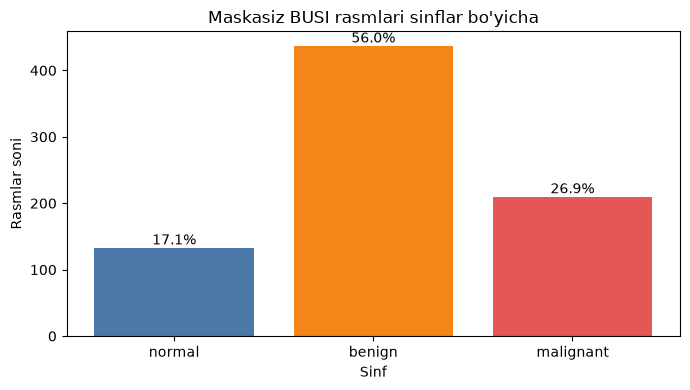

Har rasmni eng katta sinf deb aytadigan model accuracy si: 56.03%


In [3]:
def collect_samples(root: Path) -> list[tuple[Path, int]]:
    samples: list[tuple[Path, int]] = []
    for class_name in CLASSES:
        class_dir = root / class_name
        if not class_dir.is_dir():
            raise FileNotFoundError(f'Papka topilmadi: {class_dir}')
        for image_path in sorted(class_dir.glob('*.png')):
            if '_mask' not in image_path.stem.lower():
                samples.append((image_path, CLASS_TO_IDX[class_name]))
    return samples

samples = collect_samples(DATA_DIR)
counts = Counter(label for _, label in samples)
count_table = pd.DataFrame({
    'class': CLASSES,
    'images': [counts[idx] for idx in range(len(CLASSES))],
})
count_table['percent'] = 100 * count_table['images'] / count_table['images'].sum()
display(count_table.style.format({'percent': '{:.2f}%'}))

expected_counts = {'normal': 133, 'benign': 437, 'malignant': 210}
observed_counts = dict(zip(CLASSES, count_table['images']))
print(f'Jami maskasiz rasm: {len(samples)}')
print(f'Kutilgan sonlar bilan mos: {observed_counts == expected_counts}')

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(
    count_table['class'],
    count_table['images'],
    color=['#4C78A8', '#F58518', '#E45756'],
)
ax.set_title("Maskasiz BUSI rasmlari sinflar bo'yicha")
ax.set_xlabel('Sinf')
ax.set_ylabel('Rasmlar soni')
for bar, percent in zip(bars, count_table['percent']):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{percent:.1f}%',
        ha='center',
        va='bottom',
    )
plt.tight_layout()
plt.show()

majority_accuracy = 100 * count_table['images'].max() / len(samples)
print(f"Har rasmni eng katta sinf deb aytadigan model accuracy si: {majority_accuracy:.2f}%")

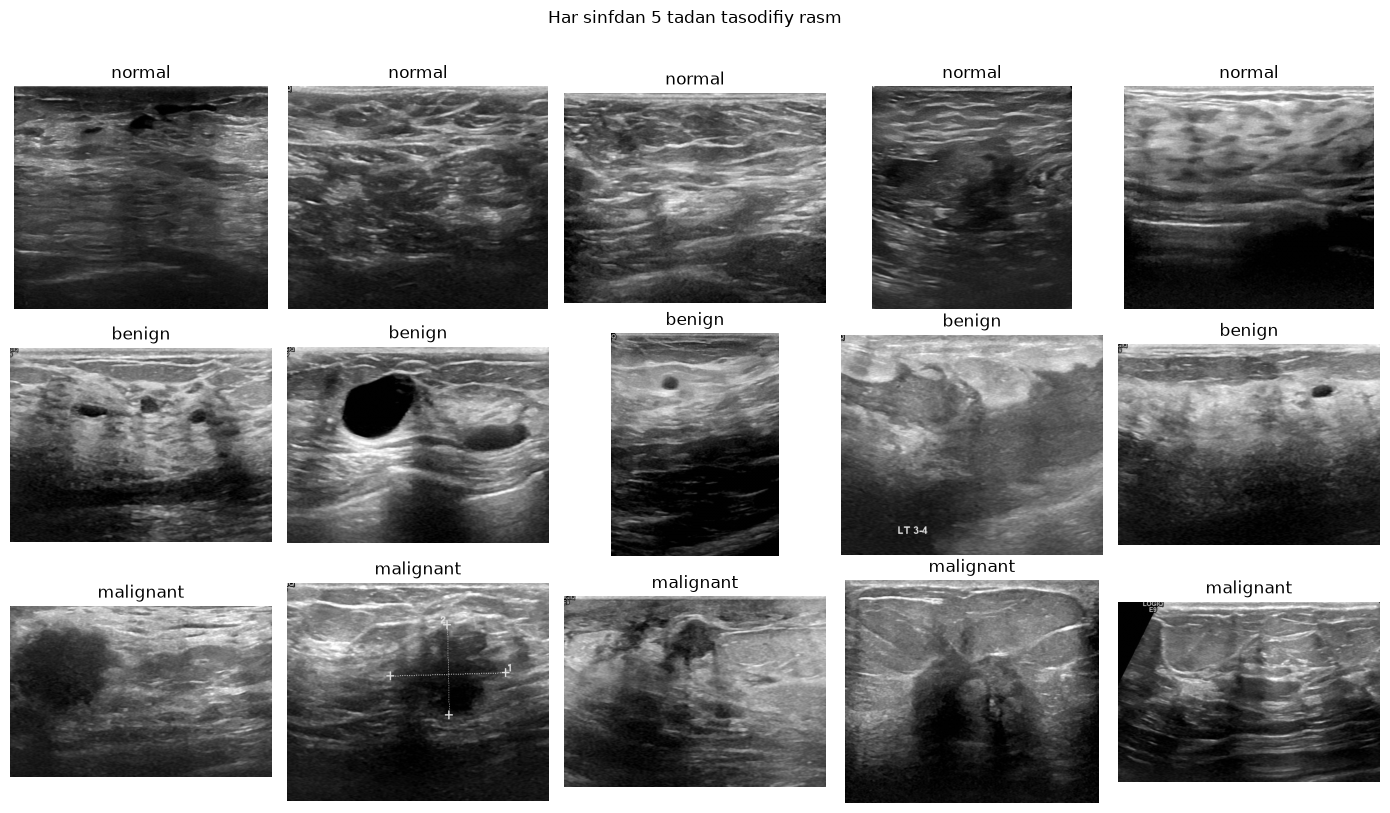

,width,height
min,190.00,310.00
max,1048.00,719.00
mean,615.68,501.45


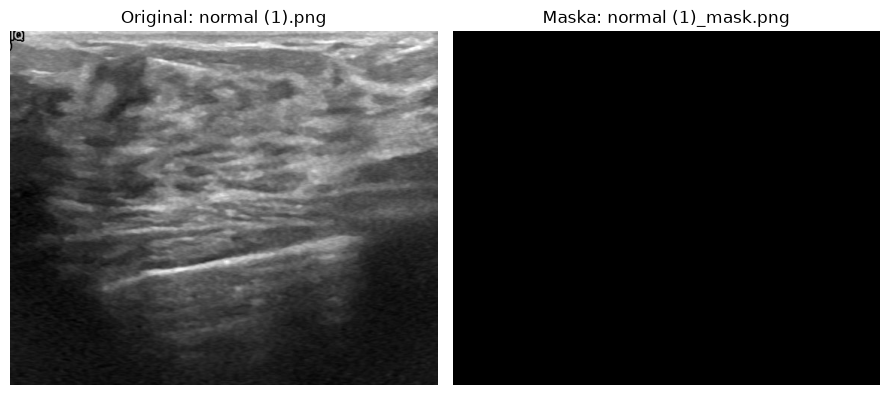

In [4]:
rng = random.Random(SEED)
fig, axes = plt.subplots(len(CLASSES), 5, figsize=(14, 8))
for row, class_name in enumerate(CLASSES):
    class_paths = [path for path, label in samples if label == CLASS_TO_IDX[class_name]]
    selected = rng.sample(class_paths, k=min(5, len(class_paths)))
    for col, ax in enumerate(axes[row]):
        ax.axis('off')
        if col < len(selected):
            with Image.open(selected[col]) as image:
                ax.imshow(image.convert('L'), cmap='gray')
            ax.set_title(class_name)
plt.suptitle('Har sinfdan 5 tadan tasodifiy rasm', y=1.01)
plt.tight_layout()
plt.show()

dimensions = []
for path, _ in samples:
    with Image.open(path) as image:
        width, height = image.size
    dimensions.append((width, height))

dimension_table = pd.DataFrame(dimensions, columns=['width', 'height'])
display(dimension_table.agg(['min', 'max', 'mean']).round(2))

def matching_masks(image_path: Path) -> list[Path]:
    return sorted(image_path.parent.glob(f'{image_path.stem}_mask*.png'))

image_with_mask = next(path for path, _ in samples if matching_masks(path))
mask_path = matching_masks(image_with_mask)[0]
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
with Image.open(image_with_mask) as image:
    axes[0].imshow(image.convert('L'), cmap='gray')
with Image.open(mask_path) as mask:
    axes[1].imshow(mask.convert('L'), cmap='gray')
axes[0].set_title(f'Original: {image_with_mask.name}')
axes[1].set_title(f'Maska: {mask_path.name}')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

In [5]:
labels = [label for _, label in samples]
train_samples, remaining_samples = train_test_split(
    samples,
    test_size=0.30,
    stratify=labels,
    random_state=SEED,
)
remaining_labels = [label for _, label in remaining_samples]
val_samples, test_samples = train_test_split(
    remaining_samples,
    test_size=0.50,
    stratify=remaining_labels,
    random_state=SEED,
)

splits = {'train': train_samples, 'validation': val_samples, 'test': test_samples}
split_table = pd.DataFrame(
    {
        split_name: [sum(label == idx for _, label in split) for idx in range(len(CLASSES))]
        for split_name, split in splits.items()
    },
    index=CLASSES,
)
split_table['total'] = split_table.sum(axis=1)
display(split_table)
print({name: len(split) for name, split in splits.items()})

train_paths = {path for path, _ in train_samples}
val_paths = {path for path, _ in val_samples}
test_paths = {path for path, _ in test_samples}
assert not train_paths & val_paths
assert not train_paths & test_paths
assert not val_paths & test_paths
assert len(train_paths | val_paths | test_paths) == len(samples)
print("Tekshiruv muvaffaqiyatli: birorta rasm ikki qismga tushmagan.")

,train,validation,test,total
normal,93,20,20,133
benign,306,65,66,437
malignant,147,32,31,210


{'train': 546, 'validation': 117, 'test': 117}
Tekshiruv muvaffaqiyatli: birorta rasm ikki qismga tushmagan.


In [6]:
def seed_worker(worker_id: int) -> None:
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

loader_generator = torch.Generator()
loader_generator.manual_seed(SEED)

class BUSIDataset(Dataset):
    def __init__(self, sample_list: list[tuple[Path, int]], transform=None):
        self.samples = list(sample_list)
        self.transform = transform

    def __len__(self) -> int:
        return len(self.samples)

    def __getitem__(self, index: int):
        path, label = self.samples[index]
        with Image.open(path) as opened_image:
            image = opened_image.convert('RGB')
        if self.transform is not None:
            image = self.transform(image)
        return image, label

def make_loader(dataset: Dataset, shuffle: bool) -> DataLoader:
    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=NUM_WORKERS,
        pin_memory=DEVICE.type == 'cuda',
        worker_init_fn=seed_worker if NUM_WORKERS else None,
        generator=loader_generator if shuffle else None,
    )

# Mean va std faqat training setdan olinadi; bu validation/test ma'lumotini sizdirmaydi.
stats_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
])
stats_dataset = BUSIDataset(train_samples, transform=stats_transform)
stats_loader = make_loader(stats_dataset, shuffle=False)

pixel_sum = torch.zeros(3)
pixel_sq_sum = torch.zeros(3)
pixel_count = 0
for images, _ in stats_loader:
    pixel_sum += images.sum(dim=(0, 2, 3))
    pixel_sq_sum += (images ** 2).sum(dim=(0, 2, 3))
    pixel_count += images.shape[0] * images.shape[2] * images.shape[3]

TRAIN_MEAN = (pixel_sum / pixel_count).tolist()
TRAIN_STD = torch.sqrt(pixel_sq_sum / pixel_count - torch.tensor(TRAIN_MEAN) ** 2).tolist()
print(f'Training mean: {TRAIN_MEAN}')
print(f'Training std:  {TRAIN_STD}')

baseline_train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.10, contrast=0.10),
    transforms.ToTensor(),
    transforms.Normalize(mean=TRAIN_MEAN, std=TRAIN_STD),
])
baseline_eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=TRAIN_MEAN, std=TRAIN_STD),
])

train_dataset = BUSIDataset(train_samples, transform=baseline_train_transform)
val_dataset = BUSIDataset(val_samples, transform=baseline_eval_transform)
test_dataset = BUSIDataset(test_samples, transform=baseline_eval_transform)
train_loader = make_loader(train_dataset, shuffle=True)
val_loader = make_loader(val_dataset, shuffle=False)
test_loader = make_loader(test_dataset, shuffle=False)
print('shuffle=True faqat train loader uchun; validation va test loaderlarda False.')

Training mean: [0.3280690908432007, 0.3280632793903351, 0.3280086815357208]
Training std:  [0.21894414722919464, 0.21894343197345734, 0.2189284712076187]
shuffle=True faqat train loader uchun; validation va test loaderlarda False.


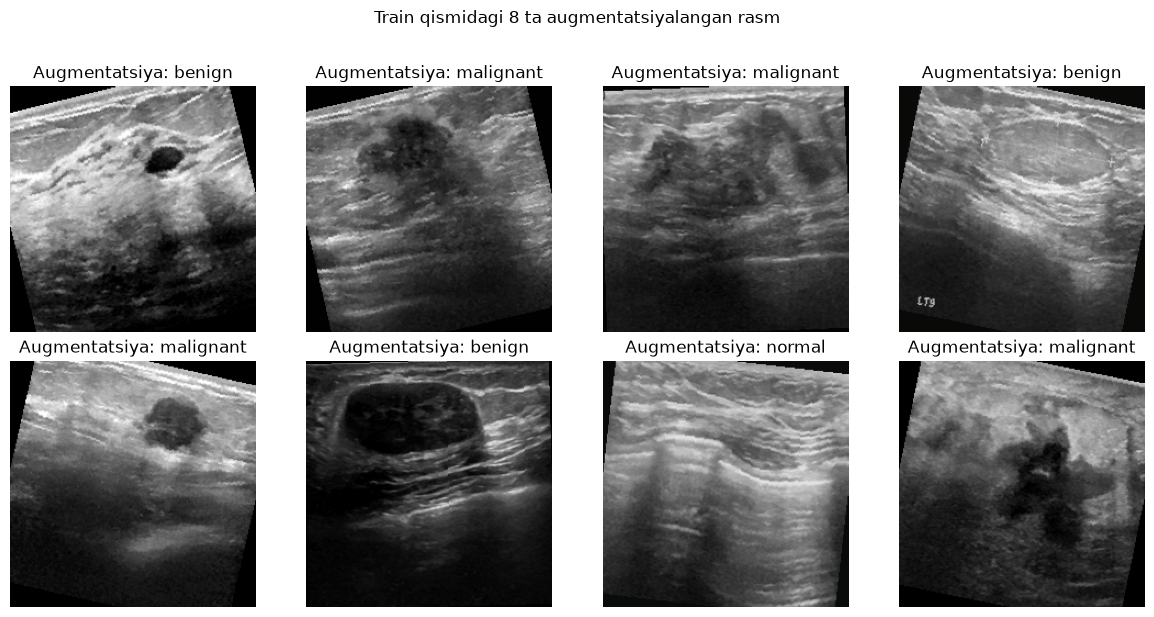

{'normal': np.float32(1.957), 'benign': np.float32(0.595), 'malignant': np.float32(1.238)}


In [7]:
def tensor_to_image(tensor: torch.Tensor, mean: list[float], std: list[float]) -> np.ndarray:
    image = tensor.detach().cpu().permute(1, 2, 0).numpy()
    image = image * np.asarray(std) + np.asarray(mean)
    return np.clip(image, 0, 1)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, index in zip(axes.ravel(), range(8)):
    image, label = train_dataset[index]
    ax.imshow(tensor_to_image(image, TRAIN_MEAN, TRAIN_STD))
    ax.set_title(f'Augmentatsiya: {CLASSES[label]}')
    ax.axis('off')
plt.suptitle("Train qismidagi 8 ta augmentatsiyalangan rasm", y=1.02)
plt.tight_layout()
plt.show()

# Bitta imbalance usuli: CrossEntropyLoss uchun class weight.
train_labels = [label for _, label in train_samples]
train_class_counts = np.bincount(train_labels, minlength=len(CLASSES))
class_weights = train_class_counts.sum() / (len(CLASSES) * train_class_counts)
class_weights = torch.tensor(class_weights, dtype=torch.float32, device=DEVICE)
print(dict(zip(CLASSES, class_weights.detach().cpu().numpy().round(3))))

In [8]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.layers(x)

class BaselineCNN(nn.Module):
    def __init__(self, num_classes: int = 3):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock(3, 16),
            ConvBlock(16, 32),
            ConvBlock(32, 64),
            ConvBlock(64, 128),
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Dropout(p=0.35),
            nn.Linear(128, num_classes),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.classifier(self.features(x))

def parameter_count(model: nn.Module, trainable_only: bool = False) -> int:
    return sum(
        parameter.numel()
        for parameter in model.parameters()
        if not trainable_only or parameter.requires_grad
    )

baseline_model = BaselineCNN(num_classes=len(CLASSES)).to(DEVICE)
images, _ = next(iter(train_loader))
with torch.no_grad():
    logits = baseline_model(images.to(DEVICE))
assert logits.shape == (images.shape[0], len(CLASSES))
print(baseline_model)
print(f'Batch output shape: {tuple(logits.shape)}')
print(f'Trainable parameters: {parameter_count(baseline_model, trainable_only=True):,}')
print(f'Device: {DEVICE}')

BaselineCNN(
  (features): Sequential(
    (0): ConvBlock(
      (layers): Sequential(
        (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (1): ConvBlock(
      (layers): Sequential(
        (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (2): ConvBlock(
      (layers): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
 

In [9]:
def run_epoch(
    model: nn.Module,
    loader: DataLoader,
    criterion: nn.Module,
    optimizer: optim.Optimizer | None = None,
) -> dict[str, float]:
    is_training = optimizer is not None
    model.train() if is_training else model.eval()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    context = torch.enable_grad() if is_training else torch.no_grad()
    with context:
        for images, labels in loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            if is_training:
                optimizer.zero_grad(set_to_none=True)

            logits = model(images)
            loss = criterion(logits, labels)

            if is_training:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * labels.size(0)
            total_correct += (logits.argmax(dim=1) == labels).sum().item()
            total_examples += labels.size(0)

    return {
        'loss': total_loss / total_examples,
        'accuracy': total_correct / total_examples,
    }

def train_model(
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    criterion: nn.Module,
    optimizer: optim.Optimizer,
    epochs: int,
    checkpoint_path: Path,
) -> tuple[dict[str, list[float]], float, float]:
    history = {
        'train_loss': [],
        'val_loss': [],
        'train_accuracy': [],
        'val_accuracy': [],
    }
    best_val_accuracy = -float('inf')
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()
    started = time.perf_counter()

    for epoch in range(1, epochs + 1):
        train_metrics = run_epoch(model, train_loader, criterion, optimizer=optimizer)
        val_metrics = run_epoch(model, val_loader, criterion, optimizer=None)
        for key, value in train_metrics.items():
            history[f'train_{key}'].append(value)
        for key, value in val_metrics.items():
            history[f'val_{key}'].append(value)

        if val_metrics['accuracy'] > best_val_accuracy:
            best_val_accuracy = val_metrics['accuracy']
            torch.save(
                {
                    'model_state': model.state_dict(),
                    'epoch': epoch,
                    'val_accuracy': best_val_accuracy,
                },
                checkpoint_path,
            )

        print(
            f'Epoch {epoch:02d}/{epochs} | '
            f'train loss {train_metrics["loss"]:.4f}, train acc {train_metrics["accuracy"]:.4f} | '
            f'val loss {val_metrics["loss"]:.4f}, val acc {val_metrics["accuracy"]:.4f}'
        )

    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()
    elapsed_seconds = time.perf_counter() - started
    checkpoint = torch.load(checkpoint_path, map_location=DEVICE)
    model.load_state_dict(checkpoint['model_state'])
    print(
        f"Best checkpoint: epoch {checkpoint['epoch']}, "
        f"val accuracy {checkpoint['val_accuracy']:.4f}"
    )
    return history, elapsed_seconds, best_val_accuracy

def plot_history(history: dict[str, list[float]], title: str) -> None:
    epochs = range(1, len(history['train_loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot(epochs, history['train_loss'], label='Train')
    axes[0].plot(epochs, history['val_loss'], label='Validation')
    axes[0].set_title(f'{title}: loss')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Cross-entropy loss')
    axes[0].legend()
    axes[1].plot(epochs, history['train_accuracy'], label='Train')
    axes[1].plot(epochs, history['val_accuracy'], label='Validation')
    axes[1].set_title(f'{title}: accuracy')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy')
    axes[1].legend()
    plt.tight_layout()
    plt.show()

Epoch 01/20 | train loss 1.1016, train acc 0.4359 | val loss 1.1348, val acc 0.2650
Epoch 02/20 | train loss 1.0594, train acc 0.3736 | val loss 1.1438, val acc 0.1709
Epoch 03/20 | train loss 1.0521, train acc 0.5147 | val loss 0.9863, val acc 0.3846
Epoch 04/20 | train loss 1.0040, train acc 0.4725 | val loss 1.0145, val acc 0.2564
Epoch 05/20 | train loss 0.9775, train acc 0.4780 | val loss 1.1222, val acc 0.3333
Epoch 06/20 | train loss 0.9883, train acc 0.4396 | val loss 0.9555, val acc 0.3932
Epoch 07/20 | train loss 0.9676, train acc 0.4634 | val loss 1.0032, val acc 0.5641
Epoch 08/20 | train loss 0.9702, train acc 0.5549 | val loss 0.9306, val acc 0.3932
Epoch 09/20 | train loss 0.9761, train acc 0.5513 | val loss 0.9739, val acc 0.3419
Epoch 10/20 | train loss 0.9182, train acc 0.4817 | val loss 0.9362, val acc 0.4444
Epoch 11/20 | train loss 0.9226, train acc 0.5861 | val loss 0.8694, val acc 0.4359
Epoch 12/20 | train loss 0.9034, train acc 0.4689 | val loss 1.1211, val acc

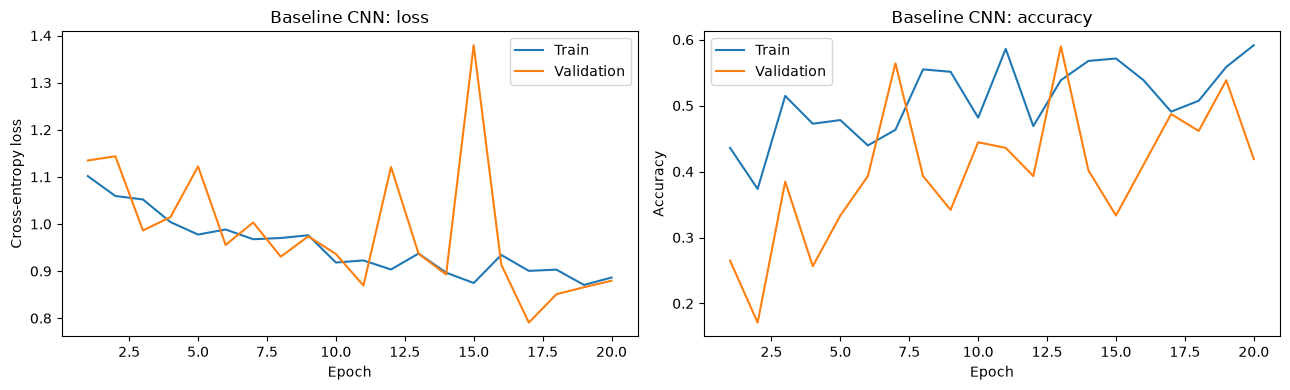

Validation loss minimumi 17-epochda; undan keyin 18-epochda oshish kuzatildi.
Overfitting bo'lsa, dropoutni kuchaytirish, ma'lumotni ko'paytirish yoki early stopping kabi usullar yordam berishi mumkin.


In [10]:
baseline_checkpoint = ARTIFACT_DIR / 'baseline_best.pt'
baseline_criterion = nn.CrossEntropyLoss(weight=class_weights)
baseline_optimizer = optim.Adam(baseline_model.parameters(), lr=1e-3)

baseline_history, baseline_train_seconds, baseline_best_val_accuracy = train_model(
    baseline_model,
    train_loader,
    val_loader,
    baseline_criterion,
    baseline_optimizer,
    epochs=EPOCHS,
    checkpoint_path=baseline_checkpoint,
)
plot_history(baseline_history, 'Baseline CNN')

val_losses = np.asarray(baseline_history['val_loss'])
min_loss_epoch = int(val_losses.argmin()) + 1
later_indices = np.arange(len(val_losses)) > val_losses.argmin()
if np.any(val_losses[later_indices] > val_losses.min()):
    first_rise_epoch = int(np.where(
        (np.arange(len(val_losses)) > val_losses.argmin())
        & (val_losses > val_losses.min())
    )[0][0]) + 1
    print(
        f'Validation loss minimumi {min_loss_epoch}-epochda; '
        f'undan keyin {first_rise_epoch}-epochda oshish kuzatildi.'
    )
else:
    print("Validation loss egri chizig'ida minimumdan keyin aniq oshish kuzatilmadi.")
print(
    "Overfitting bo'lsa, dropoutni kuchaytirish, ma'lumotni ko'paytirish "
    "yoki early stopping kabi usullar yordam berishi mumkin."
)


Baseline CNN test accuracy: 0.6239
Baseline CNN macro-F1: 0.5752
              precision    recall  f1-score   support

      normal       0.58      0.35      0.44        20
      benign       0.69      0.67      0.68        66
   malignant       0.54      0.71      0.61        31

    accuracy                           0.62       117
   macro avg       0.60      0.58      0.58       117
weighted avg       0.63      0.62      0.62       117



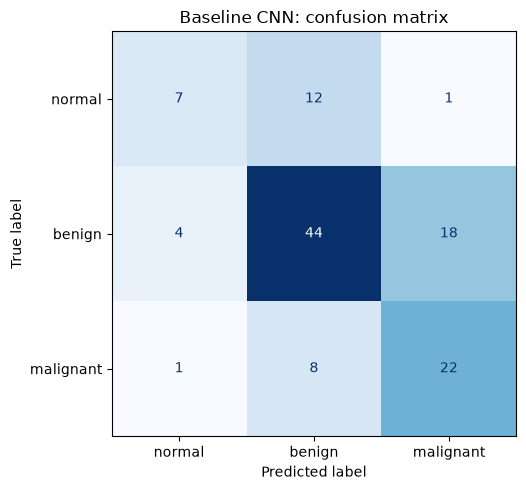

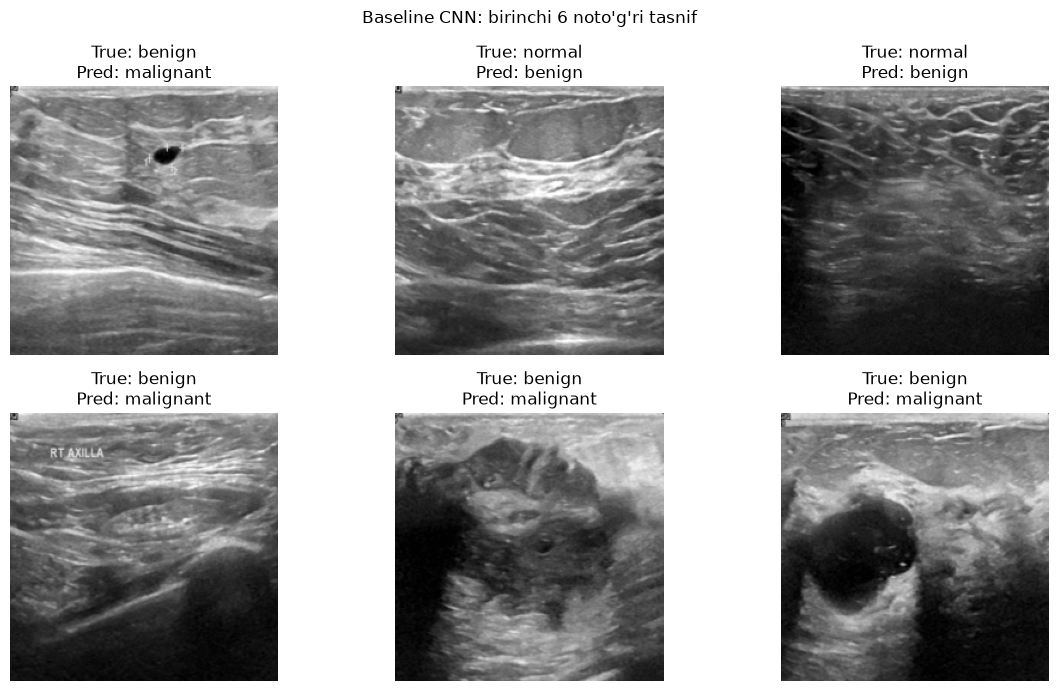

Malignant -> benign xatolari: 8
Benign -> malignant xatolari: 18
Eng ko'p chalkashgan juftlik: benign -> malignant (18)


In [11]:
def predict(model: nn.Module, loader: DataLoader) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    model.eval()
    true_labels, predicted_labels, probabilities = [], [], []
    with torch.no_grad():
        for images, labels in loader:
            logits = model(images.to(DEVICE, non_blocking=True))
            probs = torch.softmax(logits, dim=1)
            true_labels.extend(labels.numpy())
            predicted_labels.extend(probs.argmax(dim=1).cpu().numpy())
            probabilities.extend(probs.cpu().numpy())
    return np.asarray(true_labels), np.asarray(predicted_labels), np.asarray(probabilities)

def evaluate_model(
    model_name: str,
    model: nn.Module,
    loader: DataLoader,
    dataset: BUSIDataset,
    mean: list[float],
    std: list[float],
    show_errors: bool = True,
) -> dict[str, object]:
    y_true, y_pred, _ = predict(model, loader)
    accuracy = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)
    report = classification_report(
        y_true,
        y_pred,
        target_names=CLASSES,
        output_dict=True,
        zero_division=0,
    )
    matrix = confusion_matrix(y_true, y_pred, labels=range(len(CLASSES)))

    print(f'\n{model_name} test accuracy: {accuracy:.4f}')
    print(f'{model_name} macro-F1: {macro_f1:.4f}')
    print(classification_report(y_true, y_pred, target_names=CLASSES, zero_division=0))

    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=CLASSES,
    ).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'{model_name}: confusion matrix')
    plt.tight_layout()
    plt.show()

    if show_errors:
        wrong_indices = np.flatnonzero(y_true != y_pred)
        fig, axes = plt.subplots(2, 3, figsize=(12, 7))
        for ax in axes.ravel():
            ax.axis('off')
        for ax, index in zip(axes.ravel(), wrong_indices[:6]):
            image, _ = dataset[int(index)]
            ax.imshow(tensor_to_image(image, mean, std))
            ax.set_title(
                f'True: {CLASSES[y_true[index]]}\nPred: {CLASSES[y_pred[index]]}'
            )
            ax.axis('off')
        fig.suptitle(f"{model_name}: birinchi 6 noto'g'ri tasnif")
        plt.tight_layout()
        plt.show()

    off_diagonal = matrix.copy()
    np.fill_diagonal(off_diagonal, 0)
    source, target = np.unravel_index(off_diagonal.argmax(), off_diagonal.shape)
    print(
        f"Malignant -> benign xatolari: "
        f"{matrix[CLASS_TO_IDX['malignant'], CLASS_TO_IDX['benign']]}"
    )
    print(
        f"Benign -> malignant xatolari: "
        f"{matrix[CLASS_TO_IDX['benign'], CLASS_TO_IDX['malignant']]}"
    )
    print(
        f"Eng ko'p chalkashgan juftlik: "
        f"{CLASSES[source]} -> {CLASSES[target]} ({off_diagonal[source, target]})"
    )

    return {
        'test_accuracy': float(accuracy),
        'macro_f1': float(macro_f1),
        'malignant_recall': float(report['malignant']['recall']),
        'matrix': matrix,
    }

# Test set model tanlash uchun ishlatilmaydi. Bu baseline uchun yagona test chaqiruvidir.
baseline_state = torch.load(baseline_checkpoint, map_location=DEVICE)
baseline_model.load_state_dict(baseline_state['model_state'])
baseline_test_metrics = evaluate_model(
    'Baseline CNN',
    baseline_model,
    test_loader,
    test_dataset,
    TRAIN_MEAN,
    TRAIN_STD,
    show_errors=True,
)

In [12]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

resnet_train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.10, contrast=0.10),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])
resnet_eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

resnet_train_dataset = BUSIDataset(train_samples, transform=resnet_train_transform)
resnet_val_dataset = BUSIDataset(val_samples, transform=resnet_eval_transform)
resnet_test_dataset = BUSIDataset(test_samples, transform=resnet_eval_transform)
resnet_train_loader = make_loader(resnet_train_dataset, shuffle=True)
resnet_val_loader = make_loader(resnet_val_dataset, shuffle=False)
resnet_test_loader = make_loader(resnet_test_dataset, shuffle=False)

def build_resnet18(freeze_backbone: bool) -> nn.Module:
    try:
        model = models.resnet18(weights=ResNet18_Weights.DEFAULT)
    except Exception as error:
        raise RuntimeError(
            'ImageNet pretrained ResNet18 yuklanmadi. '
            'Kaggle Internet yoki cached weights mavjudligini tekshiring.'
        ) from error

    if freeze_backbone:
        for parameter in model.parameters():
            parameter.requires_grad = False

    model.fc = nn.Linear(model.fc.in_features, len(CLASSES))
    return model.to(DEVICE)

In [1]:
# Variant A: faqat oxirgi fc qatlam o'qitiladi.
resnet_a = build_resnet18(freeze_backbone=True)
resnet_a_checkpoint = ARTIFACT_DIR / 'resnet18_head_only_best.pt'
resnet_a_criterion = nn.CrossEntropyLoss(weight=class_weights)
resnet_a_optimizer = optim.Adam(
    filter(lambda parameter: parameter.requires_grad, resnet_a.parameters()),
    lr=1e-3,
)
resnet_a_history, resnet_a_train_seconds, resnet_a_best_val_accuracy = train_model(
    resnet_a,
    resnet_train_loader,
    resnet_val_loader,
    resnet_a_criterion,
    resnet_a_optimizer,
    epochs=EPOCHS,
    checkpoint_path=resnet_a_checkpoint,
)
plot_history(resnet_a_history, 'ResNet18 A - faqat fc')

# Variant B: barcha qatlamlar kichik learning rate bilan fine-tune qilinadi.
resnet_b = build_resnet18(freeze_backbone=False)
resnet_b_checkpoint = ARTIFACT_DIR / 'resnet18_finetune_best.pt'
resnet_b_criterion = nn.CrossEntropyLoss(weight=class_weights)
resnet_b_optimizer = optim.Adam(resnet_b.parameters(), lr=1e-4)
resnet_b_history, resnet_b_train_seconds, resnet_b_best_val_accuracy = train_model(
    resnet_b,
    resnet_train_loader,
    resnet_val_loader,
    resnet_b_criterion,
    resnet_b_optimizer,
    epochs=EPOCHS,
    checkpoint_path=resnet_b_checkpoint,
)
plot_history(resnet_b_history, 'ResNet18 B - fine-tuning')

NameError: name 'build_resnet18' is not defined

In [ ]:
# A va B uchun test baholashlari checkpointlar tanlangandan keyin faqat bir martadan bajariladi.
resnet_a.load_state_dict(torch.load(resnet_a_checkpoint, map_location=DEVICE)['model_state'])
resnet_a_test_metrics = evaluate_model(
    'ResNet18 A',
    resnet_a,
    resnet_test_loader,
    resnet_test_dataset,
    IMAGENET_MEAN,
    IMAGENET_STD,
    show_errors=False,
)

resnet_b.load_state_dict(torch.load(resnet_b_checkpoint, map_location=DEVICE)['model_state'])
resnet_b_test_metrics = evaluate_model(
    'ResNet18 B',
    resnet_b,
    resnet_test_loader,
    resnet_test_dataset,
    IMAGENET_MEAN,
    IMAGENET_STD,
    show_errors=False,
)

comparison = pd.DataFrame([
    {
        'Model': 'Baseline CNN',
        'Total parameters': parameter_count(baseline_model),
        'Trainable parameters': parameter_count(baseline_model, trainable_only=True),
        'Training time (s)': baseline_train_seconds,
        'Best val accuracy': baseline_best_val_accuracy,
        'Test accuracy': baseline_test_metrics['test_accuracy'],
        'Macro-F1': baseline_test_metrics['macro_f1'],
        'Malignant recall': baseline_test_metrics['malignant_recall'],
    },
    {
        'Model': 'ResNet18 A: fc only',
        'Total parameters': parameter_count(resnet_a),
        'Trainable parameters': parameter_count(resnet_a, trainable_only=True),
        'Training time (s)': resnet_a_train_seconds,
        'Best val accuracy': resnet_a_best_val_accuracy,
        'Test accuracy': resnet_a_test_metrics['test_accuracy'],
        'Macro-F1': resnet_a_test_metrics['macro_f1'],
        'Malignant recall': resnet_a_test_metrics['malignant_recall'],
    },
    {
        'Model': 'ResNet18 B: fine-tuning',
        'Total parameters': parameter_count(resnet_b),
        'Trainable parameters': parameter_count(resnet_b, trainable_only=True),
        'Training time (s)': resnet_b_train_seconds,
        'Best val accuracy': resnet_b_best_val_accuracy,
        'Test accuracy': resnet_b_test_metrics['test_accuracy'],
        'Macro-F1': resnet_b_test_metrics['macro_f1'],
        'Malignant recall': resnet_b_test_metrics['malignant_recall'],
    },
])
display(comparison.style.format({
    'Training time (s)': '{:.1f}',
    'Best val accuracy': '{:.4f}',
    'Test accuracy': '{:.4f}',
    'Macro-F1': '{:.4f}',
    'Malignant recall': '{:.4f}',
}))
best_row = comparison.sort_values(
    ['Macro-F1', 'Malignant recall'],
    ascending=False,
).iloc[0]
print(
    f"Eng yaxshi model (macro-F1, so'ng malignant recall bo'yicha): "
    f"{best_row['Model']}"
)